In [ ]:
!pip install pyspark -q

In [ ]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.window import Window

In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import tensorflow as tf
from sklearn.metrics import mean_squared_error, mean_absolute_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Creación y configuración de la SparkSession para ejecutar el pipeline de ETL de manera local aprovechando todos los núcleos disponibles.
spark = SparkSession.builder.appName("PJM_Energy_ETL").master("local[*]").getOrCreate()

In [ ]:
# Lectura del archivo CSV original con el historial de consumo eléctrico de PJM utilizando PySpark.
df = spark.read.csv("pjme_extracted.csv", header=True, inferSchema=True)

In [ ]:
# Transformación de la columna de fecha y hora a formato timestamp y casendose la columna de consumo (MW) a tipo double.
df = df.withColumn("datetime", F.to_timestamp("datetime")).withColumn("pjme_mw", F.col("pjme_mw").cast("double"))

In [ ]:
# Limpieza de registros nulos, valores negativos/cero y eliminación de posibles marcas de tiempo duplicadas.
df = df.filter((F.col("pjme_mw")).isNotNull() & (F.col("pjme_mw")>0)).dropDuplicates(["datetime"])

In [ ]:
# Configuración de especificaciones de ventana para el cálculo de características de desfase (lags) y medias móviles temporales.
window_spec_lag = Window.orderBy("datetime")
window_spec_7d = Window.orderBy("datetime").rowsBetween(-168, 0)

In [ ]:
# Extracción de variables temporales (hora, día de la semana, indicador de fin de semana, mes, año), junto con características de desfase de 24 horas y promedio móvil de 7 días.
df_features = df.withColumn("hour", F.hour("datetime")) \
.withColumn("dayofweek", F.dayofweek("datetime")) \
.withColumn("is_weekend", F.when(F.col("dayofweek").isin([1, 7]),1).otherwise(0)) \
.withColumn("month", F.month("datetime")) \
.withColumn("year", F.year("datetime")) \
.withColumn("lag_24h", F.lag("pjme_mw", 24).over(window_spec_lag)) \
.withColumn("rolling_avg_7d", F.avg("pjme_mw").over(window_spec_7d))

In [ ]:
# Eliminación de registros con valores nulos generados tras el cálculo de las ventanas temporales (lags).
df_clean = df_features.filter(F.col("lag_24h").isNotNull())

In [ ]:
# Persistencia de los datos limpios y enriquecidos en formato Apache Parquet, particionados por año y mes para optimizar futuras consultas.
df_clean.write \
    .mode("overwrite") \
    .partitionBy("year", "month") \
    .parquet("pjme_clean.parquet")

In [ ]:
# Carga de los datos limpios a un DataFrame de Pandas para la fase de modelado local, ordenándolos cronológicamente e inspeccionando las primeras filas.
df2 = pd.read_parquet("pjme_clean.parquet")
df2 = df2.sort_values("datetime")
df2.head()

,datetime,pjme_mw,daily_avg_mw,hour,dayofweek,is_weekend,lag_24h,rolling_avg_7d,year,month
0,2002-01-02 01:00:00,28121.0,34261.541667,1,4,0,30393.0,30901.640000,2002,1
1,2002-01-02 02:00:00,27437.0,34261.541667,2,4,0,29265.0,30768.384615,2002,1
2,2002-01-02 03:00:00,27301.0,34261.541667,3,4,0,28357.0,30639.962963,2002,1
3,2002-01-02 04:00:00,27533.0,34261.541667,4,4,0,27899.0,30529.000000,2002,1
4,2002-01-02 05:00:00,28405.0,34261.541667,5,4,0,28057.0,30455.758621,2002,1


In [ ]:
# Selección de las columnas relevantes para el modelo y conversión del DataFrame a un arreglo NumPy.
features = ["pjme_mw", "daily_avg_mw", "hour", "dayofweek", "is_weekend", "month", "lag_24h", "rolling_avg_7d"]
data = df2[features].values

In [ ]:
# Instanciación del escalador MinMax para normalizar los valores numéricos y facilitar la convergencia de los modelos.
scaler = MinMaxScaler()

In [ ]:
# División cronológica del conjunto de datos (80% entrenamiento, 20% prueba) respetando el orden temporal de las series de tiempo.
train_size = int(len(data)*0.8)
train_data, test_data = data[:train_size], data[train_size:]

In [ ]:
# Definición de función auxiliar para estructurar los datos en ventanas deslizantes de secuencias temporales (X) y su respectivo objetivo (y).
def create_temporal_sequences(data, seq_lenght=24):
  X = []
  y = []
  for i in range(len(data)-seq_lenght):
    X.append(data[i:i+seq_lenght, :])
    y.append(data[i+seq_lenght, 0])
  return np.array(X), np.array(y)

In [ ]:
# Ajuste del escalador con los datos de entrenamiento y transformación tanto del conjunto de entrenamiento como de prueba para evitar fugas de datos (data leakage).
train_scaled = scaler.fit_transform(train_data)
test_scaled = scaler.transform(test_data)

In [ ]:
# Generación de las matrices de entrada y salida secuenciales para los modelos predictivos utilizando ventanas de 24 horas.
X_train, y_train = create_temporal_sequences(train_scaled)
X_test, y_test = create_temporal_sequences(test_scaled)

In [ ]:
# Configuración del modelo Random Forest Regressor y reformateo (aplanamiento) de las secuencias tridimensionales a bidimensionales requeridas por Scikit-Learn.
rf = RandomForestRegressor(n_estimators=100, max_depth=15, n_jobs=-1, random_state=42)
X_train_rf = X_train.reshape((X_train.shape[0], -1))
X_test_rf = X_test.reshape((X_test.shape[0], -1))

In [ ]:
# Entrenamiento del modelo de Random Forest con los datos históricos aplanados.
rf.fit(X_train_rf, y_train)

RandomForestRegressor(max_depth=15, n_jobs=-1, random_state=42)

In [ ]:
# Generación de predicciones sobre el conjunto de prueba utilizando el modelo de Random Forest.
y_pred_rf = rf.predict(X_test_rf)

In [ ]:
# Cálculo e impresión de las métricas de error (RMSE y MAE) para evaluar el rendimiento del modelo Random Forest.
rmse = np.sqrt(mean_squared_error(y_test, y_pred_rf))
mae = mean_absolute_error(y_test, y_pred_rf)
print(f"RMSE (Random Forest): {rmse:.2f}")
print(f"MAE (Random Forest): {mae:.2f}")

RMSE (Random Forest): 0.01
MAE (Random Forest): 0.01


In [ ]:
# Definición de la arquitectura de la red neuronal recurrente LSTM con capas de Dropout para prevenir sobreajuste (overfitting).
model = Sequential([
    LSTM(64, return_sequences=True, input_shape=(X_train.shape[1], X_train.shape[2])),
    Dropout(0.2),
    LSTM(32, return_sequences=False),
    Dropout(0.2),
    Dense(1)
])

model.compile(optimizer='adam', loss='mse')

early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [ ]:
# Entrenamiento del modelo LSTM utilizando validación cruzada y un callback de Early Stopping para detener el entrenamiento si no mejora la pérdida de validación.
model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=64,
    validation_data=(X_test, y_test),
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/20
1817/1817 ━━━━━━━━━━━━━━━━━━━━ 63s 33ms/step - loss: 0.0027 - val_loss: 4.5471e-04
Epoch 2/20
1817/1817 ━━━━━━━━━━━━━━━━━━━━ 57s 32ms/step - loss: 7.2831e-04 - val_loss: 3.1842e-04
Epoch 3/20
1817/1817 ━━━━━━━━━━━━━━━━━━━━ 58s 32ms/step - loss: 5.3334e-04 - val_loss: 3.2493e-04
Epoch 4/20
1817/1817 ━━━━━━━━━━━━━━━━━━━━ 59s 32ms/step - loss: 4.3684e-04 - val_loss: 1.7520e-04
Epoch 5/20
1817/1817 ━━━━━━━━━━━━━━━━━━━━ 58s 32ms/step - loss: 3.6979e-04 - val_loss: 1.3996e-04
Epoch 6/20
1817/1817 ━━━━━━━━━━━━━━━━━━━━ 81s 31ms/step - loss: 3.2185e-04 - val_loss: 8.4399e-05
Epoch 7/20
1817/1817 ━━━━━━━━━━━━━━━━━━━━ 57s 31ms/step - loss: 2.9608e-04 - val_loss: 1.1286e-04
Epoch 8/20
1817/1817 ━━━━━━━━━━━━━━━━━━━━ 58s 32ms/step - loss: 2.8702e-04 - val_loss: 1.6439e-04
Epoch 9/20
1817/1817 ━━━━━━━━━━━━━━━━━━━━ 82s 32ms/step - loss: 2.7997e-04 - val_loss: 6.8986e-05
Epoch 10/20
1817/1817 ━━━━━━━━━━━━━━━━━━━━ 59s 32ms/step - loss: 2.6681e-04 - val_loss: 5.2722e-05
Epoch 11/20
1817/1817 ━

In [ ]:
# Generación de predicciones sobre el conjunto de prueba utilizando el modelo de Deep Learning (LSTM).
y_pred_lstm = model.predict(X_test)

908/908 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step


In [ ]:
# Cálculo e impresión de las métricas de error (RMSE y MAE) para evaluar el rendimiento del modelo LSTM.
rmse = np.sqrt(mean_squared_error(y_test, y_pred_lstm))
mae = mean_absolute_error(y_test, y_pred_lstm)
print(f"RMSE (LSTM): {rmse:.2f}")
print(f"MAE (LSTM): {mae:.2f}")

RMSE (LSTM): 0.01
MAE (LSTM): 0.01


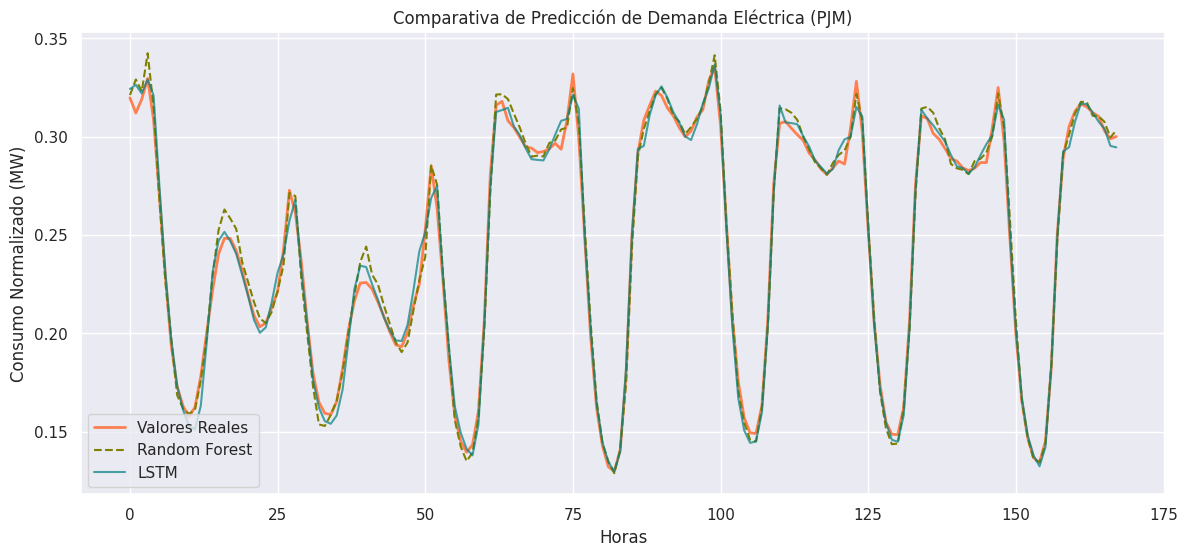

In [ ]:
# Generación de un gráfico comparativo de líneas para visualizar el comportamiento de los valores reales frente a las predicciones de Random Forest y LSTM durante las primeras 168 horas (1 semana).
sns.set_theme(style="darkgrid")
fig, ax = plt.subplots(figsize=(14, 6))

n_horas = 168

ax.plot(y_test[:n_horas], label = "Valores Reales", color = "coral", linewidth=2)
ax.plot(y_pred_rf[:n_horas], label = "Random Forest", color = "olive", linestyle="--")
ax.plot(y_pred_lstm[:n_horas], label="LSTM", color="teal", alpha=0.7)

ax.set_title("Comparativa de Predicción de Demanda Eléctrica (PJM)")
ax.set_xlabel("Horas")
ax.set_ylabel("Consumo Normalizado (MW)")
ax.legend()
plt.show()